<a href="https://colab.research.google.com/github/salvin2000/Deep-Learning-projects/blob/main/predicting_butterfly_species_using_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loading dataset from kaggle

In [ ]:
import os
import kagglehub
import pathlib
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg



# Download the latest version of the butterfly images dataset
path = kagglehub.dataset_download("gpiosenka/butterfly-images40-species")

print("Dataset downloaded to:", path)
print("Contents of the downloaded directory:", os.listdir(path))

Using Colab cache for faster access to the 'butterfly-images40-species' dataset.
Dataset downloaded to: /kaggle/input/butterfly-images40-species
Contents of the downloaded directory: ['training.csv.csv', 'butterflies and moths.csv', 'EfficientNetB0-100-(224 X 224)- 97.59.h5', 'valid', 'test', 'train']


In [ ]:

# walk through 10 classes if the food image data
for dirpath, dirnames, filenames in os.walk(path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")


There are 3 directories and 3 images in '/kaggle/input/butterfly-images40-species'.
There are 100 directories and 0 images in '/kaggle/input/butterfly-images40-species/valid'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/PIPEVINE SWALLOW'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/ARCIGERA FLOWER MOTH'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/SIXSPOT BURNET MOTH'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/ATLAS MOTH'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/GREY HAIRSTREAK'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/MALACHITE'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/POPINJAY'.
There are 0 directories and 5 images in '/kaggle/input/butterfly-images40-species/valid/CA

In [ ]:
# Update paths with the correct downloaded kagglehub path
base_dir = path
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
valid_dir = os.path.join(base_dir, "valid")

In [ ]:
train_dir

'/kaggle/input/butterfly-images40-species/train'

In [ ]:
test_dir

'/kaggle/input/butterfly-images40-species/test'

In [ ]:
valid_dir

'/kaggle/input/butterfly-images40-species/valid'

In [ ]:
# let's get the class names

data_dir= pathlib.Path(train_dir)
class_names = np.array(sorted([item.name for item in data_dir.glob('*') if item.is_dir()]))
print(class_names)


['ADONIS' 'AFRICAN GIANT SWALLOWTAIL' 'AMERICAN SNOOT' 'AN 88' 'APPOLLO'
 'ARCIGERA FLOWER MOTH' 'ATALA' 'ATLAS MOTH' 'BANDED ORANGE HELICONIAN'
 'BANDED PEACOCK' 'BANDED TIGER MOTH' 'BECKERS WHITE'
 'BIRD CHERRY ERMINE MOTH' 'BLACK HAIRSTREAK' 'BLUE MORPHO'
 'BLUE SPOTTED CROW' 'BROOKES BIRDWING' 'BROWN ARGUS' 'BROWN SIPROETA'
 'CABBAGE WHITE' 'CAIRNS BIRDWING' 'CHALK HILL BLUE' 'CHECQUERED SKIPPER'
 'CHESTNUT' 'CINNABAR MOTH' 'CLEARWING MOTH' 'CLEOPATRA'
 'CLODIUS PARNASSIAN' 'CLOUDED SULPHUR' 'COMET MOTH' 'COMMON BANDED AWL'
 'COMMON WOOD-NYMPH' 'COPPER TAIL' 'CRECENT' 'CRIMSON PATCH'
 'DANAID EGGFLY' 'EASTERN COMA' 'EASTERN DAPPLE WHITE'
 'EASTERN PINE ELFIN' 'ELBOWED PIERROT' 'EMPEROR GUM MOTH'
 'GARDEN TIGER MOTH' 'GIANT LEOPARD MOTH' 'GLITTERING SAPPHIRE'
 'GOLD BANDED' 'GREAT EGGFLY' 'GREAT JAY' 'GREEN CELLED CATTLEHEART'
 'GREEN HAIRSTREAK' 'GREY HAIRSTREAK' 'HERCULES MOTH'
 'HUMMING BIRD HAWK MOTH' 'INDRA SWALLOW' 'IO MOTH' 'Iphiclus sister'
 'JULIA' 'LARGE MARBLE' 'LUNA MOTH

# Visualizing the images

In [ ]:
def random_image(target_dir, class_i):

  folder = os.path.join(target_dir,class_i)

  random_image  = random.sample(os.listdir(folder),1)
  print(random_image)

  img2= mpimg.imread(os.path.join(folder, random_image[0]))

  plt.imshow(img2)
  plt.title(f"name: {class_i}")
  plt.axis("off");
  plt.show()

  print(f"image shape: {img2.shape}") # show the shape of the image



['020.jpg']


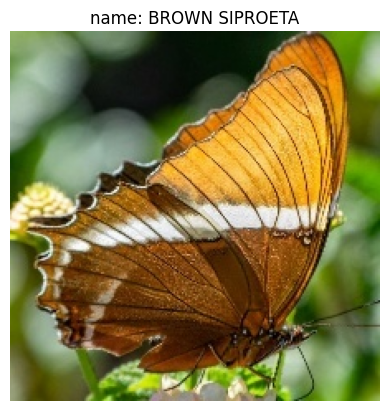

image shape: (224, 224, 3)


In [ ]:
random_image(target_dir=train_dir , class_i=random.choice(class_names))

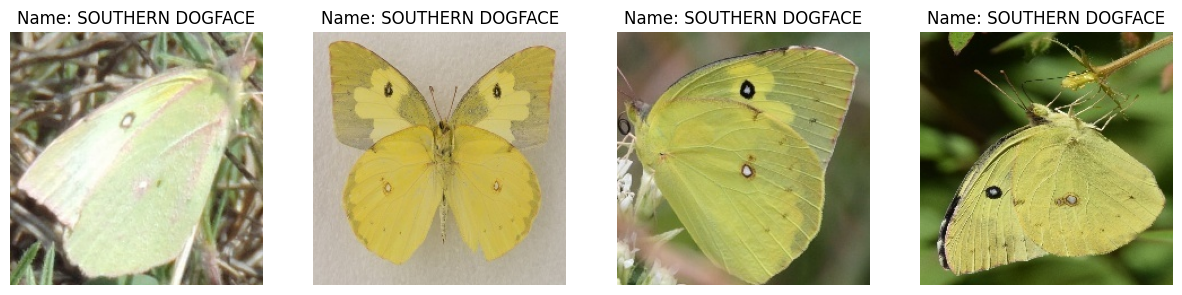

In [ ]:
def same_species(target_dir, random_class, num_images=4):


  folder = os.path.join(target_dir, random_class)

  # Get all image file names in this folder
  all_images = os.listdir(folder)

  # Sample random images
  sample_size = min(num_images, len(all_images))
  random_images = random.sample(all_images, sample_size)

  # Plot the images side-by-side
  plt.figure(figsize=(15, 5))
  for i, img_name in enumerate(random_images):
    plt.subplot(1, sample_size, i + 1)
    img_path = os.path.join(folder, img_name)
    img = mpimg.imread(img_path)
    plt.imshow(img)
    plt.title(f"Name: {random_class}")
    plt.axis("off")
  plt.show()

# Call the function with a random class
same_species(target_dir=train_dir, random_class=random.choice(class_names))

# preparing the data

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

image_shape=(224,224)
Batch_size=32

train_datagen = ImageDataGenerator(rescale=1/255.)

test_datagen = ImageDataGenerator(rescale=1/255.)

train_datagen_augmented = ImageDataGenerator(rescale=1/255.,
                                             rotation_range=0.2, #how much do you want to rotate an image
                                             shear_range=0.2, # how much do you wnat to shear an image
                                             zoom_range=0.2,# zoom in randomly on an image
                                             width_shift_range=0.2, # move your image around on the x-axis
                                             height_shift_range=0.2, # move your image around on the y-axis
                                             horizontal_flip=True) # do you want to flip an image?


print("training images")

train_data_butterfly = train_datagen.flow_from_directory(train_dir,
                                                        target_size=image_shape,
                                                         batch_size=Batch_size,
                                                         class_mode="categorical")

print("testing images")

test_data_butterfly = test_datagen.flow_from_directory(test_dir,
                                                        target_size=image_shape,
                                                        batch_size=Batch_size,
                                                        class_mode="categorical")

print("training images")

# import data and augment it and shuffle from training directory
train_data_augmented_shuffled = train_datagen_augmented.flow_from_directory(train_dir,
                                                                            target_size=image_shape,
                                                                            class_mode="categorical",
                                                                            batch_size=Batch_size,
                                                                            shuffle=True)




training images
Found 12594 images belonging to 100 classes.
testing images
Found 500 images belonging to 100 classes.
training images
Found 12594 images belonging to 100 classes.


# creating a model



In [ ]:
# plot the validation adn training curves seperately
def plot_loss_curves(history):
    """
    Returns seperate loss curves for training and validation metrics.
    """
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]

    epochs = range(len(history.history["loss"]))


    #plot loss
    plt.plot(epochs, loss, label="training_loss")
    plt.plot(epochs,val_loss,label="val_loss")
    plt.title("loss")
    plt.xlabel("epoch")
    plt.legend()

    #plot accuracy
    plt.figure()
    plt.plot(epochs, accuracy, label="training_accuracy")
    plt.plot(epochs,val_accuracy,label="val_accuracy")
    plt.title("accuracy")
    plt.xlabel("epoch")
    plt.legend();



# lets use transfer learning. Transfer learing has ready made  models that has high accuracy and low loss.



In [ ]:
# create tensorboard callback (functionized beacuse we need to create a new one for each model)
import datetime

def create_tensorboard_callback(dir_name, experiment_name):
  log_dir = dir_name + "/" + experiment_name + "/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
  tensorboard_callback = tf_keras.callbacks.TensorBoard(log_dir=log_dir)
  print(f"Saving TensorBoard log files to: {log_dir}")
  return tensorboard_callback

In [ ]:
# link address for efficientnet
efficientnet_url = "https://tfhub.dev/tensorflow/efficientnet/b0/feature-vector/1"

In [ ]:
# import dependencies
import tensorflow_hub as hub
from tensorflow.keras import layers

import tf_keras
IMAGE_SHAPE = (224, 224)

def create_model(model_url, num_classes=10):
  feature_extractor_layer = hub.KerasLayer(model_url,
                                           trainable=False,
                                           name="feature_extraction_layer",
                                           input_shape=IMAGE_SHAPE+(3,))

  model = tf_keras.Sequential([
      feature_extractor_layer,
      tf_keras.layers.Dense(num_classes, activation="softmax", name="output_layer")
  ])

  return model



/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [ ]:
# let's create a function to plot our loss curves...
import matplotlib.pyplot as plt

# plot the validation and training curves
def plot_loss_curves(history):

  loss= history.history["loss"]
  val_loss = history.history["val_loss"]

  accuracy = history.history["accuracy"]
  val_accuracy = history.history["val_accuracy"]

  epochs = range(len(history.history["loss"]))

  # plot loss
  plt.plot(epochs, loss, label="training_loss")
  plt.plot(epochs, val_loss, label="val_loss")
  plt.title("loss")
  plt.xlabel("epochs")
  plt.legend()

  # plot accuracy
  plt.figure()
  plt.plot(epochs, accuracy, label="training_accuracy")
  plt.plot(epochs, val_accuracy, label="val_accuracy ")
  plt.title("accuracy")
  plt.xlabel("Epochs")
  plt.legend();



# create model using efficientnet

In [ ]:
# create efficientnetB0 feature extractor model
efficientnet_model = create_model(model_url=efficientnet_url, num_classes=len(class_names))

#compile efficientnet model
efficientnet_model.compile(loss="categorical_crossentropy",
                           optimizer = tf_keras.optimizers.Adam(),
                           metrics=["accuracy"])


efficientnet_history = efficientnet_model.fit(train_data_butterfly,
                                              epochs=5,
                                              steps_per_epoch=len(train_data_butterfly),
                                              validation_data=test_data_butterfly,
                                              validation_steps=len(test_data_butterfly),
                                              callbacks=[create_tensorboard_callback(dir_name="tensorflow_hub",
                                                                                     experiment_name="efficientnetb7")]

                                              )


Saving TensorBoard log files to: tensorflow_hub/efficientnetb7/20261105-164931
Epoch 1/5
394/394 [==============================] - 111s 256ms/step - loss: 1.6918 - accuracy: 0.7111 - val_loss: 0.6889 - val_accuracy: 0.8860
Epoch 2/5
394/394 [==============================] - 42s 106ms/step - loss: 0.5304 - accuracy: 0.9035 - val_loss: 0.4039 - val_accuracy: 0.9400
Epoch 3/5
394/394 [==============================] - 42s 106ms/step - loss: 0.3460 - accuracy: 0.9356 - val_loss: 0.2949 - val_accuracy: 0.9560
Epoch 4/5
394/394 [==============================] - 43s 109ms/step - loss: 0.2603 - accuracy: 0.9495 - val_loss: 0.2746 - val_accuracy: 0.9380
Epoch 5/5
394/394 [==============================] - 43s 109ms/step - loss: 0.2077 - accuracy: 0.9616 - val_loss: 0.1994 - val_accuracy: 0.9560


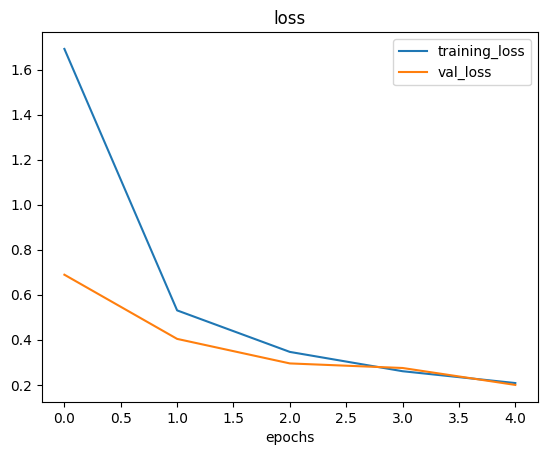

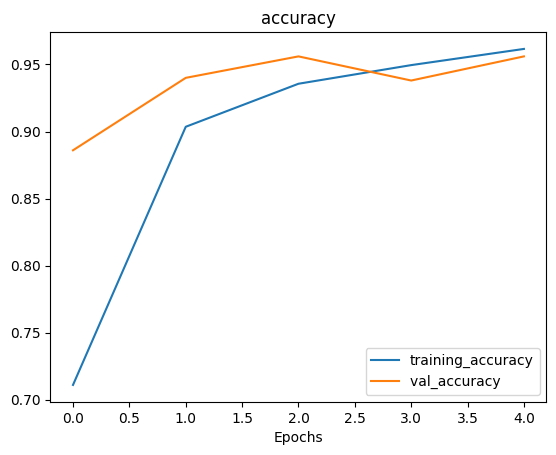

In [ ]:
plot_loss_curves(efficientnet_history)

efficientnet performed well

now lets predict the butterflies

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import requests

from google.colab import files
uploaded = files.upload()

Saving butterfly 5.webp to butterfly 5.webp


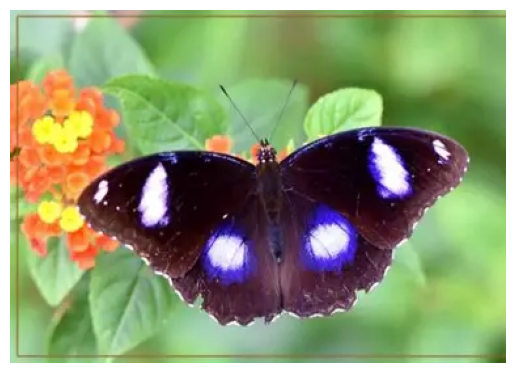

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Use just the filename - no C:\ path
img = Image.open("butterfly 5.webp")
fly = np.array(img)

plt.imshow(fly)
plt.axis(False)
plt.show()

In [ ]:
fly.shape

(270, 379, 3)

In [ ]:
import tensorflow as tf

In [ ]:
# create a function to import and image and resize it to bew able to be used with our model
def load_and_prep_image(filename, img_shape=224):
    """
    Reads and image from filename, turns it into a tensor and reshape it
    to (img_shape, img_shape, colour_channels).
    """
    # read in the iamge
    img = tf.io.read_file(filename)
    #decode the read file into a tensor
    img = tf.image.decode_image(img)
    # resize the image
    img = tf.image.resize(img, size=[img_shape, img_shape])
    # rescale the image (get all values between 0 and 1)
    img = img/255.
    return img


In [ ]:
# load in and preprocess our custom image using its filename
fly = load_and_prep_image(filename="butterfly 5.webp")

In [ ]:
fly

<tf.Tensor: shape=(1, 224, 224, 3), dtype=float32, numpy=
array([[[[0.69411767, 0.84867895, 0.8202891 ],
         [0.6911349 , 0.8591059 , 0.81049764],
         [0.6945203 , 0.87396944, 0.789911  ],
         ...,
         [0.5701504 , 0.76407045, 0.4506389 ],
         [0.5996888 , 0.7948131 , 0.47015688],
         [0.60784316, 0.80311626, 0.47289914]],

        [[0.69253755, 0.85218835, 0.81243443],
         [0.6968313 , 0.85767263, 0.79965657],
         [0.6985947 , 0.85912114, 0.77195376],
         ...,
         [0.57796496, 0.75986266, 0.4486734 ],
         [0.5986889 , 0.7831972 , 0.4630426 ],
         [0.60180324, 0.7864145 , 0.46008846]],

        [[0.68898815, 0.8562187 , 0.7970763 ],
         [0.69442326, 0.8528162 , 0.7814991 ],
         [0.7078957 , 0.8480413 , 0.75212044],
         ...,
         [0.5908504 , 0.7477317 , 0.443319  ],
         [0.60017025, 0.758521  , 0.44691393],
         [0.6003151 , 0.758666  , 0.4392157 ]],

        ...,

        [[0.6583845 , 0.8662276 , 

In [ ]:
expanded_fly = tf.expand_dims(fly, axis=0)

In [ ]:
pred=efficientnet_model.predict(fly)

1/1 [==============================] - 1s 1s/step


In [ ]:
# we can index the predicted class by finding the index of the highest probability value
pred_class = class_names[pred.argmax()]
pred_class

np.str_('DANAID EGGFLY')

DANAID EGGFLY is the name of the butterfly species

In [ ]:
def show_species_image(species_name, target_dir=train_dir):

    # Ensure the species name is formatted in uppercase to match the directory names
    species_name = species_name.upper()
    species_folder = os.path.join(target_dir, species_name)

    if not os.path.exists(species_folder):
        print(f"Error: Species '{species_name}' not found in '{target_dir}'.")
        print("Please check the species name. Examples:", class_names[:5])
        return

    # Get random image from the species directory
    images = os.listdir(species_folder)
    random_img_name = random.choice(images)
    img_path = os.path.join(species_folder, random_img_name)

    # Load and show the image
    img = mpimg.imread(img_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Species: {species_name} ({random_img_name})")
    plt.axis("off")
    plt.show()

    print(f"Image shape: {img.shape}")

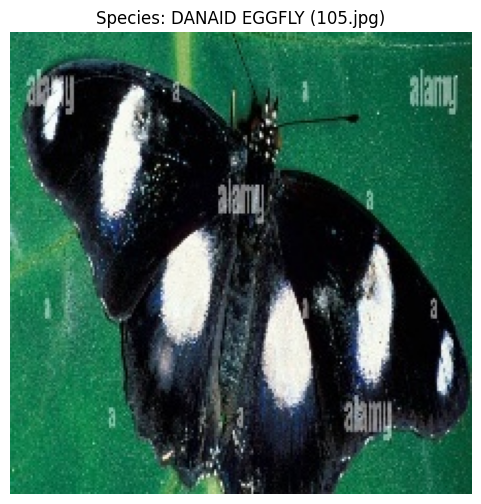

Image shape: (224, 224, 3)


In [ ]:
# Example usage:
show_species_image(species_name=pred_class)